In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv(r"C:\Users\Lenovo\Downloads\customer_shopping_behavior.csv")

In [3]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Customer ID,3900.0,1950.500000,1125.977353,1.0,975.75,1950.5,2925.25,3900.0
Age,3900.0,44.068462,15.207589,18.0,31.00,44.0,57.00,70.0
Purchase Amount (USD),3900.0,59.764359,23.685392,20.0,39.00,60.0,81.00,100.0
Review Rating,3863.0,3.750065,0.716983,2.5,3.10,3.8,4.40,5.0
Previous Purchases,3900.0,25.351538,14.447125,1.0,13.00,25.0,38.00,50.0


In [8]:
df.describe(include='object').T

,count,unique,top,freq
Gender,3900,2,Male,2652
Item Purchased,3900,25,Blouse,171
Category,3900,4,Clothing,1737
Location,3900,50,Montana,96
Size,3900,4,M,1755
Color,3900,25,Olive,177
Season,3900,4,Spring,999
Subscription Status,3900,2,No,2847
Shipping Type,3900,6,Free Shipping,675
Discount Applied,3900,2,No,2223


In [9]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [10]:
df.isnull().mean()  # Null values in percentage

Customer ID               0.000000
Age                       0.000000
Gender                    0.000000
Item Purchased            0.000000
Category                  0.000000
Purchase Amount (USD)     0.000000
Location                  0.000000
Size                      0.000000
Color                     0.000000
Season                    0.000000
Review Rating             0.009487
Subscription Status       0.000000
Shipping Type             0.000000
Discount Applied          0.000000
Promo Code Used           0.000000
Previous Purchases        0.000000
Payment Method            0.000000
Frequency of Purchases    0.000000
dtype: float64

In [11]:
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform( lambda x: x.fillna(x.median()))

In [12]:
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

In [13]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ','_')
df = df.rename(columns={'purchase_amount_(usd)':'purchase_amount'})

In [14]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

In [15]:
labels = ['Young Adult', 'Adult', 'Middle-aged', 'Senior']
df['age_group'] = pd.qcut(df['age'], q=4, labels = labels)

In [16]:
df[['age','age_group']].head(10)

,age,age_group
0,55,Middle-aged
1,19,Young Adult
2,50,Middle-aged
3,21,Young Adult
4,45,Middle-aged
5,46,Middle-aged
6,63,Senior
7,27,Young Adult
8,26,Young Adult
9,57,Middle-aged


<Axes: ylabel='count'>

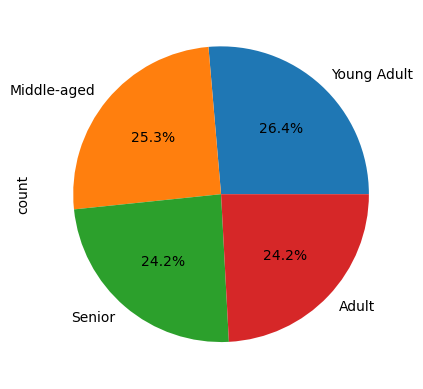

In [21]:
df['age_group'].value_counts().plot(kind= 'pie', autopct = "%0.1f%%")

<Axes: ylabel='count'>

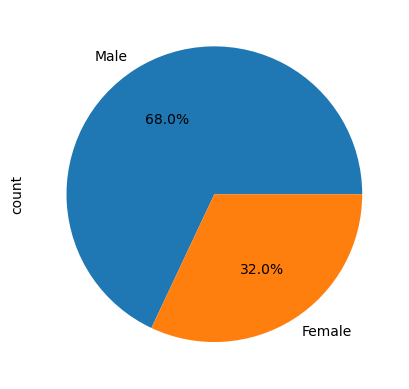

In [28]:
df['gender'].value_counts().plot(kind= 'pie', autopct = "%0.1f%%")

<Axes: >

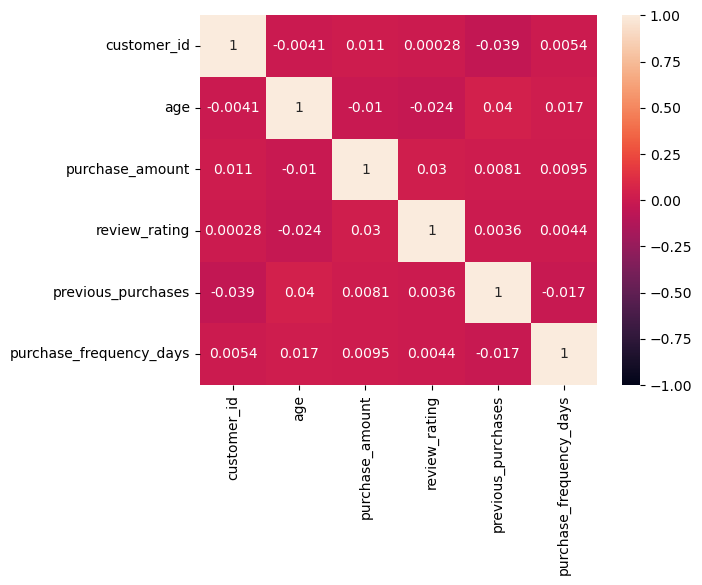

In [35]:
df_num = df.select_dtypes(include=np.number).columns
cor = df[df_num].corr()
sns.heatmap(cor,annot = True, vmax= 1, vmin= -1)

In [48]:
df_cat = df.select_dtypes(include='object').columns
df_cat

Index(['gender', 'item_purchased', 'category', 'location', 'size', 'color',
       'season', 'subscription_status', 'shipping_type', 'discount_applied',
       'payment_method', 'frequency_of_purchases'],
      dtype='object')

<Axes: ylabel='count'>

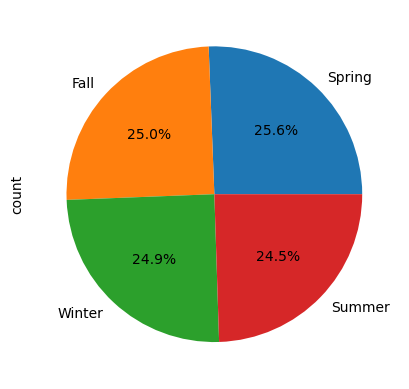

In [63]:
df['season'].value_counts().plot(kind= 'pie',autopct= "%0.1f%%")

<Axes: xlabel='color'>

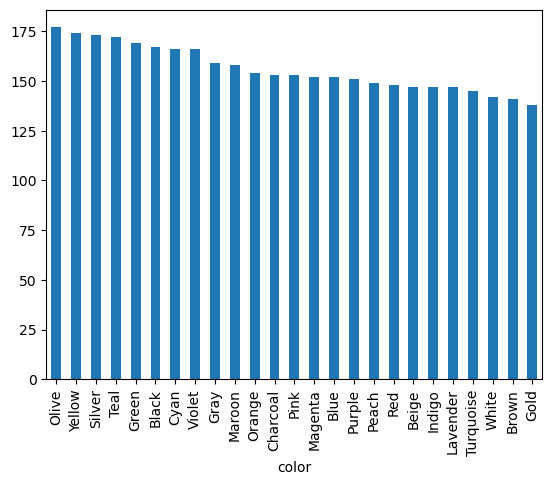

In [64]:
df['color'].value_counts().plot(kind = 'bar')

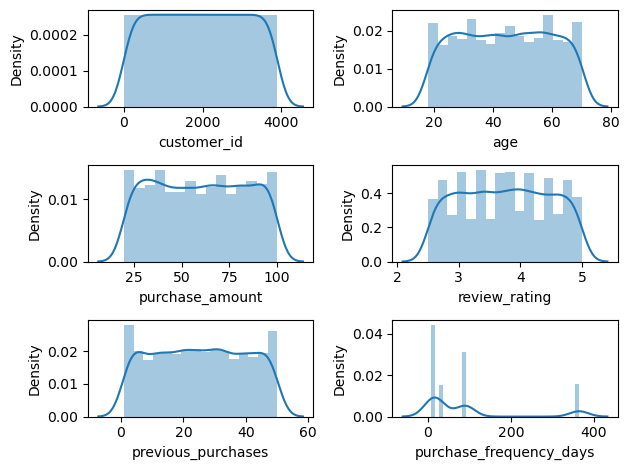

In [47]:
a = 1
for i in df_num:
    plt.subplot(3,2,a)
    sns.distplot(df[i])
    a += 1
plt.tight_layout()
plt.show()

<Axes: xlabel='size'>

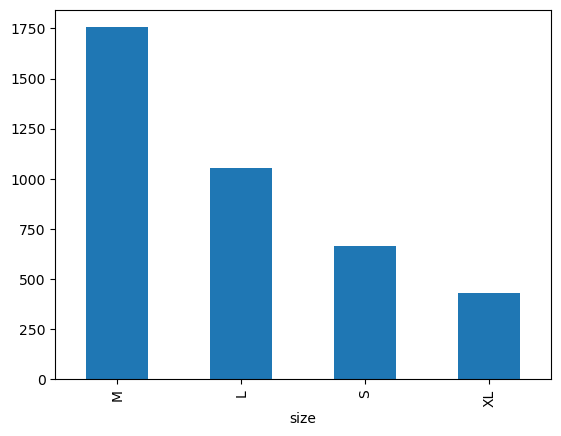

In [51]:
df['size'].value_counts().plot(kind= 'bar', )

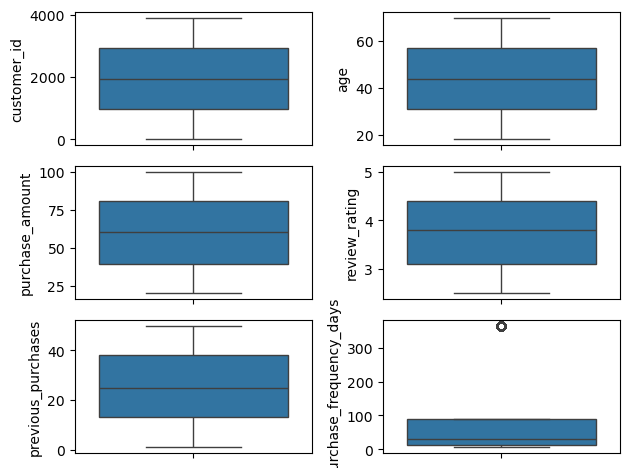

In [52]:
a = 1 
for i in df_num:
    plt.subplot(3,2,a)
    sns.boxplot(df[i])
    a += 1
plt.tight_layout()
plt.show()

<Axes: ylabel='count'>

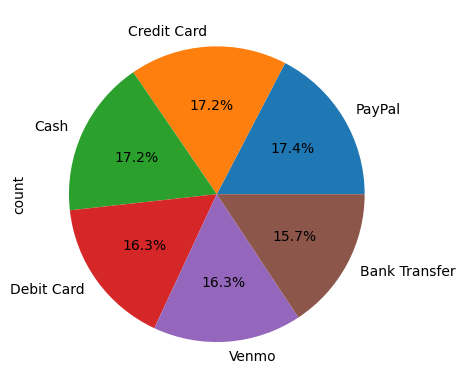

In [55]:
df['payment_method'].value_counts().plot(kind= 'pie', autopct = "%0.1f%%")

In [22]:
frequency_mapping = {
    'Fortnightly': 14,
    'Weekly': 7,
    'Monthly': 30,
    'Quarterly': 90,
    'Bi-Weekly': 14,
    'Annually': 365,
    'Every 3 Months': 90
}

df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)

In [23]:
df[['purchase_frequency_days','frequency_of_purchases']].head(10)

,purchase_frequency_days,frequency_of_purchases
0,14,Fortnightly
1,14,Fortnightly
2,7,Weekly
3,7,Weekly
4,365,Annually
5,7,Weekly
6,90,Quarterly
7,7,Weekly
8,365,Annually
9,90,Quarterly


In [68]:
pd.pivot_table(data = df, values= 'purchase_amount', index = 'frequency_of_purchases', columns='gender',aggfunc="sum")

gender,Female,Male
frequency_of_purchases,,
Annually,11136,23283
Bi-Weekly,11264,21936
Every 3 Months,11562,23526
Fortnightly,9637,22370
Monthly,11088,21722
Quarterly,10468,23303
Weekly,10036,21750


In [24]:
df[['discount_applied','promo_code_used']].head(10)

,discount_applied,promo_code_used
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,Yes,Yes
5,Yes,Yes
6,Yes,Yes
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


In [25]:
(df['discount_applied'] == df['promo_code_used']).all()

np.True_

In [26]:
df = df.drop('promo_code_used', axis=1)

In [27]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='object')

In [ ]:
import psycopg2
import sqlalchemy

print("Installed successfully!")

In [ ]:
!pip install psycopg2-binary sqlalchemy

In [ ]:
import sys
!{sys.executable} -m pip install psycopg2-binary sqlalchemy

In [ ]:
import psycopg2

In [ ]:
from sqlalchemy import create_engine

# Step 1: Connect to PostgreSQL
# Replace placeholders with your actual details
username = "postgres"      # default user
password = "8056" # the password you set during installation
host = "localhost"         # if running locally
port = "5432"              # default PostgreSQL port
database = "customer_behavior"    # the database you created in pgAdmin

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

# Step 2: Load DataFrame into PostgreSQL
table_name = "customer"   # choose any table name
df.to_sql(table_name, engine, if_exists="replace", index=False)

print(f"Data successfully loaded into table '{table_name}' in database '{database}'.")


In [ ]:
import tkinter as tk
from tkinter import ttk

root = tk.Tk()
root.mainloop()